# Step 1 — Data Acquisition: Public School Data (NCES CCD + EDGE, 2024–25)

This notebook extracts public-school data from four NCES source files and combines them into **one school-level
dataset** covering every jurisdiction NCES reports: the 50 states, the District of Columbia, the U.S. territories,
and the Bureau of Indian Education.

| # | Source file | What it gives each school |
|---|---|---|
| 1 | School directory | ID, name, district ID and name, address, status, type, level, grade span |
| 2 | School membership | Total enrollment (student count) |
| 3 | School staff | Teacher full-time equivalents (FTE) |
| 4 | School geocodes (EDGE) | Latitude, longitude, county, locale |

All files are for the **2024–25 school year**, the latest year NCES has published. (2025–26 appears in the NCES year
menu but has no files yet.)

## 1. Download the source files

Download the four files below by hand and place them, **still zipped**, in the folders shown. Paths are relative to
the project root.

### 1.1 School directory, membership and staff (NCES Common Core of Data)

1. Open **https://nces.ed.gov/ccd/files.asp**
2. Set the three dropdowns:
   - first dropdown: **Nonfiscal**
   - **Level:** **School**
   - **School Year:** **2024 - 2025**
3. The results are grouped by component. Under each of **Directory**, **Membership** and **Staff**, click the data
   file link labelled **"Flat and SAS Files"**. If a notice window opens, continue to the download.
4. Move the three zip files into `data/raw/ccd_2024_25/`.

| Component | File | Size | Direct link |
|---|---|---|---|
| Directory | `ccd_sch_029_2425_w_1a_073025.zip` | 13 MB | https://nces.ed.gov/ccd/Data/zip/ccd_sch_029_2425_w_1a_073025.zip |
| Membership | `ccd_sch_052_2425_l_1a_073025.zip` | 213 MB | https://nces.ed.gov/ccd/Data/zip/ccd_sch_052_2425_l_1a_073025.zip |
| Staff | `ccd_sch_059_2425_l_1a_073025.zip` | 6 MB | https://nces.ed.gov/ccd/Data/zip/ccd_sch_059_2425_l_1a_073025.zip |

Each component also has a **"Companion File"** link (an Excel workbook). It is the official column dictionary —
useful for reference, not needed to run this notebook.

### 1.2 School geocodes (NCES EDGE)

1. Open **https://nces.ed.gov/programs/edge/Geographic/SchoolLocations**
2. Under **Public Schools**, download **2024–25**.
3. Move the zip into `data/raw/edge_2024_25/`.

| File | Size | Direct link |
|---|---|---|
| `EDGE_GEOCODE_PUBLICSCH_2425.zip` | 30 MB | https://nces.ed.gov/programs/edge/data/EDGE_GEOCODE_PUBLICSCH_2425.zip |

Field definitions are in the EDGE technical documentation:
https://nces.ed.gov/programs/edge/docs/EDGE_GEOCODE_PUBLIC_TECHDOC.pdf

### 1.3 Expected folder layout

```
data/raw/
├── ccd_2024_25/
│   ├── ccd_sch_029_2425_w_1a_073025.zip
│   ├── ccd_sch_052_2425_l_1a_073025.zip
│   └── ccd_sch_059_2425_l_1a_073025.zip
└── edge_2024_25/
    └── EDGE_GEOCODE_PUBLICSCH_2425.zip
```

## 2. Setup

In [1]:
import shutil
import subprocess
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")

print(f"pandas {pd.__version__} | numpy {np.__version__} | seaborn {sns.__version__}")

pandas 3.0.2 | numpy 2.4.4 | seaborn 0.12.2


In [2]:
SCHOOL_YEAR_LABEL = "2024_25"

# The notebook lives in notebooks/; all data paths are relative to the project root.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_CCD_DIR = PROJECT_ROOT / "data" / "raw" / "ccd_2024_25"
RAW_EDGE_DIR = PROJECT_ROOT / "data" / "raw" / "edge_2024_25"
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"

SOURCE_FILES = {
    "school_directory": RAW_CCD_DIR / "ccd_sch_029_2425_w_1a_073025.zip",
    "school_membership": RAW_CCD_DIR / "ccd_sch_052_2425_l_1a_073025.zip",
    "school_staff": RAW_CCD_DIR / "ccd_sch_059_2425_l_1a_073025.zip",
    "school_geocode": RAW_EDGE_DIR / "EDGE_GEOCODE_PUBLICSCH_2425.zip",
}

# Record counts NCES publishes for each file (the "Introduction" sheet of each companion workbook).
# Every load below is checked against these numbers.
PUBLISHED_RECORDS = {
    "school_directory": 102_178,
    "school_membership": 11_172_292,
    "school_staff": 100_237,
}
PUBLISHED_SCHOOLS_IN_MEMBERSHIP = 99_420


def check(condition: bool, failure_message: str) -> None:
    # Stops the notebook with a plain-language message instead of continuing with bad data.
    if not condition:
        raise ValueError(failure_message)


missing_files = [str(path.relative_to(PROJECT_ROOT)) for path in SOURCE_FILES.values() if not path.exists()]
check(not missing_files, f"Source files not found: {missing_files}. Download them as described in section 1.")
pd.DataFrame(
    {
        "file": [path.name for path in SOURCE_FILES.values()],
        "megabytes": [round(path.stat().st_size / 1e6, 1) for path in SOURCE_FILES.values()],
    },
    index=list(SOURCE_FILES),
)

,file,megabytes
school_directory,ccd_sch_029_2425_w_1a_073025.zip,13.4
school_membership,ccd_sch_052_2425_l_1a_073025.zip,212.7
school_staff,ccd_sch_059_2425_l_1a_073025.zip,5.9
school_geocode,EDGE_GEOCODE_PUBLICSCH_2425.zip,30.4


In [3]:
# Every column is read as text first, so IDs keep their leading zeros (e.g. "0100005") and nothing is
# converted by guesswork. Only empty cells become missing values; numbers are converted explicitly later.
CSV_TEXT_OPTIONS = {"dtype": str, "keep_default_na": False, "na_values": [""]}


def open_zip_member(zip_path: Path, member_name: str):
    # The membership zip is compressed with Deflate64, which Python's zipfile module cannot decompress.
    # For that file the system `unzip` tool streams the CSV directly, so the 2.3 GB file never touches disk.
    try:
        return zipfile.ZipFile(zip_path).open(member_name)
    except NotImplementedError:
        check(
            shutil.which("unzip") is not None,
            f"open_zip_member: {zip_path.name} needs the `unzip` command, which is not installed.",
        )
        return subprocess.Popen(["unzip", "-p", str(zip_path), member_name], stdout=subprocess.PIPE).stdout


def read_ccd_csv(dataset: str, **read_csv_options):
    zip_path = SOURCE_FILES[dataset]
    return pd.read_csv(
        open_zip_member(zip_path, zip_path.name.replace(".zip", ".csv")),
        **CSV_TEXT_OPTIONS,
        **read_csv_options,
    )

## 3. Load each source file

### 3.1 School directory

In [4]:
SCHOOL_DIRECTORY_COLUMNS = {
    "NCESSCH": "school_id",
    "LEAID": "district_id",
    "SCH_NAME": "school_name",
    "LEA_NAME": "district_name",
    "ST": "admin_state",
    "STATENAME": "admin_state_name",
    "FIPST": "admin_state_fips",
    "LSTREET1": "street",
    "LCITY": "city",
    "LSTATE": "address_state",
    "LZIP": "zipcode",
    "SY_STATUS": "status_start_of_year_code",
    "SY_STATUS_TEXT": "status_start_of_year",
    "UPDATED_STATUS_TEXT": "status_updated",
    "SCH_TYPE_TEXT": "school_type",
    "CHARTER_TEXT": "charter",
    "LEVEL": "level",
    "GSLO": "lowest_grade",
    "GSHI": "highest_grade",
    "OUT_OF_STATE_FLAG": "out_of_state_flag",
}

school_directory = read_ccd_csv("school_directory", usecols=list(SCHOOL_DIRECTORY_COLUMNS)).rename(
    columns=SCHOOL_DIRECTORY_COLUMNS
)
school_directory = school_directory[list(SCHOOL_DIRECTORY_COLUMNS.values())]

# NCES counts a school as operational when its start-of-year status is Open (1), New (3), Added (4),
# Changed Boundary/Agency (5) or Reopened (8). This rule reproduces the OPERATIONAL_SCHOOLS count in the
# NCES district directory for every district.
OPERATIONAL_STATUS_CODES = {"1", "3", "4", "5", "8"}
school_directory["is_operational"] = school_directory["status_start_of_year_code"].isin(
    OPERATIONAL_STATUS_CODES
)

check(
    len(school_directory) == PUBLISHED_RECORDS["school_directory"],
    f"School directory has {len(school_directory):,} rows; NCES publishes {PUBLISHED_RECORDS['school_directory']:,}.",
)
check(school_directory["school_id"].is_unique, "School directory: school_id is not unique.")
check(
    school_directory["school_id"].str.len().eq(12).all(),
    "School directory: some school_id values are not 12 characters (leading zeros lost?).",
)
check(
    school_directory["district_id"].str.len().eq(7).all(),
    "School directory: some district_id values are not 7 characters.",
)
print(
    f"Schools loaded: {len(school_directory):,} (matches NCES published count); operational: {school_directory['is_operational'].sum():,}"
)
school_directory.head(3)

Schools loaded: 102,178 (matches NCES published count); operational: 100,237


,school_id,district_id,school_name,district_name,admin_state,admin_state_name,admin_state_fips,street,city,address_state,zipcode,status_start_of_year_code,status_start_of_year,status_updated,school_type,charter,level,lowest_grade,highest_grade,out_of_state_flag,is_operational
0,010000500870,0100005,Albertville Middle School,Albertville City,AL,ALABAMA,01,600 E Alabama Ave,Albertville,AL,35950,1,Open,Open,Regular School,No,Middle,07,08,No,True
1,010000500871,0100005,Albertville High School,Albertville City,AL,ALABAMA,01,402 E McCord Ave,Albertville,AL,35950,1,Open,Open,Regular School,No,High,09,12,No,True
2,010000500879,0100005,Albertville Intermediate School,Albertville City,AL,ALABAMA,01,901 W McKinney Ave,Albertville,AL,35950,1,Open,Open,Regular School,No,Middle,05,06,No,True


### 3.2 School membership (enrollment)

This file has one row per school × grade × race × sex — about 11 million rows. A school's **total enrollment** is the
single row where `TOTAL_INDICATOR` equals `"Education Unit Total"` (definition from the membership companion file).
The file is read in chunks and only those total rows are kept (about 10 seconds).

In [5]:
ENROLLMENT_TOTAL_INDICATOR = "Education Unit Total"
MEMBERSHIP_COLUMNS = [
    "NCESSCH",
    "GRADE",
    "RACE_ETHNICITY",
    "SEX",
    "STUDENT_COUNT",
    "TOTAL_INDICATOR",
    "DMS_FLAG",
]

membership_rows_read = 0
enrollment_chunks = []
for chunk in read_ccd_csv("school_membership", usecols=MEMBERSHIP_COLUMNS, chunksize=2_000_000):
    membership_rows_read += len(chunk)
    enrollment_chunks.append(chunk[chunk["TOTAL_INDICATOR"] == ENROLLMENT_TOTAL_INDICATOR])
enrollment_rows = pd.concat(enrollment_chunks, ignore_index=True)

check(
    membership_rows_read == PUBLISHED_RECORDS["school_membership"],
    f"Membership: read {membership_rows_read:,} rows; NCES publishes {PUBLISHED_RECORDS['school_membership']:,}. The file may be incomplete.",
)
check(
    len(enrollment_rows) == PUBLISHED_SCHOOLS_IN_MEMBERSHIP,
    f"Membership: {len(enrollment_rows):,} total rows; expected one per school ({PUBLISHED_SCHOOLS_IN_MEMBERSHIP:,}).",
)
check(
    enrollment_rows["NCESSCH"].is_unique, "Membership: a school has more than one 'Education Unit Total' row."
)
# A true school total is not broken down by any category.
for category_column in ["GRADE", "RACE_ETHNICITY", "SEX"]:
    check(
        enrollment_rows[category_column].eq("No Category Codes").all(),
        f"Membership: total rows unexpectedly split by {category_column}.",
    )

enrollment = pd.DataFrame(
    {
        "school_id": enrollment_rows["NCESSCH"],
        "student_count": pd.to_numeric(enrollment_rows["STUDENT_COUNT"]).astype("Int64"),
        "student_count_flag": enrollment_rows["DMS_FLAG"],
    }
)
check(
    enrollment.loc[enrollment["student_count"].isna(), "student_count_flag"].ne("Reported").all(),
    "Membership: a blank enrollment is flagged 'Reported' — the source has an unexplained gap.",
)
print(f"Membership rows read: {membership_rows_read:,} → school totals: {len(enrollment):,}")
print(f"Total students: {enrollment['student_count'].sum():,}")
enrollment["student_count_flag"].value_counts(dropna=False).to_frame("schools")

Membership rows read: 11,172,292 → school totals: 99,420
Total students: 49,343,524


,schools
student_count_flag,
Reported,99245
Missing,74
Suppressed,54
Not reported,47


### 3.3 School staff (teacher FTE)

In [6]:
staff_raw = read_ccd_csv("school_staff", usecols=["NCESSCH", "TEACHERS", "TOTAL_INDICATOR", "DMS_FLAG"])

check(
    len(staff_raw) == PUBLISHED_RECORDS["school_staff"],
    f"Staff: {len(staff_raw):,} rows; NCES publishes {PUBLISHED_RECORDS['school_staff']:,}.",
)
check(staff_raw["NCESSCH"].is_unique, "Staff: a school appears more than once.")
check(
    staff_raw["TOTAL_INDICATOR"].eq("Education Unit Total").all(), "Staff: some rows are not school totals."
)

staff = pd.DataFrame(
    {
        "school_id": staff_raw["NCESSCH"],
        # TEACHERS is full-time-equivalent, so it can be fractional (e.g. 66.5).
        "teacher_fte": pd.to_numeric(staff_raw["TEACHERS"]).astype("Float64"),
        "teacher_fte_flag": staff_raw["DMS_FLAG"],
    }
)
check(
    staff.loc[staff["teacher_fte"].isna(), "teacher_fte_flag"].ne("Reported").all(),
    "Staff: a blank teacher count is flagged 'Reported'.",
)
print(f"Staff records: {len(staff):,}; total teacher FTE: {staff['teacher_fte'].sum():,.1f}")
staff["teacher_fte_flag"].value_counts(dropna=False).to_frame("schools")

Staff records: 100,237; total teacher FTE: 3,177,661.7


,schools
teacher_fte_flag,
Reported,96174
Not reported,2588
Missing,1375
Suppressed,100


### 3.4 School geocodes (EDGE)

The EDGE zip holds the same table as `.TXT`, `.xlsx` and `.sas7bdat`. The pipe-delimited `.TXT` is used because it
keeps coordinates exactly as published (`34.260200`), while Excel stores them as binary floats
(`34.260200000000005`). The `.TXT` has no header row, so column names are taken from the `.xlsx` header.

Field meanings (from the EDGE technical documentation):
- `STATE` — "reported location state": the state in the school's street address.
- `STFIP`, `CNTY`, `NMCNTY` — state and county assigned **from the latitude and longitude**, i.e. where the school
  physically is. This is the location to use for climate zones later.
- `LOCALE` — NCES urban-centric locale code, from 11 (City – Large) to 43 (Rural – Remote).

In [7]:
with zipfile.ZipFile(SOURCE_FILES["school_geocode"]) as edge_zip:
    edge_column_names = pd.read_excel(
        edge_zip.open("EDGE_GEOCODE_PUBLICSCH_2425.xlsx"), nrows=0
    ).columns.tolist()
    edge_raw = pd.read_csv(
        edge_zip.open("EDGE_GEOCODE_PUBLICSCH_2425.TXT"),
        sep="|",
        header=None,
        names=edge_column_names,
        **CSV_TEXT_OPTIONS,
    )

geocode = pd.DataFrame(
    {
        "school_id": edge_raw["NCESSCH"],
        "latitude": pd.to_numeric(edge_raw["LAT"]),
        "longitude": pd.to_numeric(edge_raw["LON"]),
        "location_state_fips": edge_raw["STFIP"],
        "county_fips": edge_raw["CNTY"],
        "county_name": edge_raw["NMCNTY"],
        "locale_code": edge_raw["LOCALE"],
        "geocode_address_state": edge_raw["STATE"],
    }
)

check(
    len(geocode) == len(school_directory),
    f"EDGE has {len(geocode):,} schools; the directory has {len(school_directory):,}.",
)
check(geocode["school_id"].is_unique, "EDGE: school_id is not unique.")
check(
    set(geocode["school_id"]) == set(school_directory["school_id"]),
    "EDGE and the school directory list different schools.",
)
check(
    geocode["latitude"].between(-90, 90).all() and geocode["longitude"].between(-180, 180).all(),
    "EDGE: coordinates out of the valid range.",
)
check(geocode["county_fips"].str.len().eq(5).all(), "EDGE: some county FIPS codes are not 5 digits.")
check(
    (geocode["county_fips"].str[:2] == geocode["location_state_fips"]).all(),
    "EDGE: county FIPS does not start with its state FIPS.",
)
print(f"Geocodes loaded: {len(geocode):,}; schools with coordinates: {geocode['latitude'].notna().sum():,}")
geocode.head(3)

Geocodes loaded: 102,178; schools with coordinates: 102,178


,school_id,latitude,longitude,location_state_fips,county_fips,county_name,locale_code,geocode_address_state
0,010000500870,34.260200,-86.206200,01,01095,Marshall County,32,AL
1,010000500871,34.261772,-86.204911,01,01095,Marshall County,32,AL
2,010000500879,34.273557,-86.220154,01,01095,Marshall County,32,AL


## 4. Audit

A standard profile of every dataset: size, types, missing values and duplicates. Surprises are reported here,
before anything is joined.

In [8]:
def profile(frame: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame(
        {
            "dtype": frame.dtypes.astype(str),
            "missing": frame.isna().sum(),
            "missing_pct": (frame.isna().mean() * 100).round(2),
            "distinct_values": frame.nunique(),
        }
    )


for name, frame in {
    "school_directory": school_directory,
    "enrollment": enrollment,
    "staff": staff,
    "geocode": geocode,
}.items():
    print(
        f"\n=== {name}: {frame.shape[0]:,} rows × {frame.shape[1]} columns | fully duplicated rows: {frame.duplicated().sum()}"
    )
    display(profile(frame))


=== school_directory: 102,178 rows × 21 columns | fully duplicated rows: 0


,dtype,missing,missing_pct,distinct_values
school_id,str,0,0.0,102178
district_id,str,0,0.0,18587
school_name,str,0,0.0,89804
district_name,str,0,0.0,18236
admin_state,str,0,0.0,57
admin_state_name,str,0,0.0,57
admin_state_fips,str,0,0.0,57
street,str,0,0.0,92823
city,str,0,0.0,14469
address_state,str,0,0.0,56



=== enrollment: 99,420 rows × 3 columns | fully duplicated rows: 0


,dtype,missing,missing_pct,distinct_values
school_id,str,0,0.00,99420
student_count,Int64,175,0.18,2988
student_count_flag,str,0,0.00,4



=== staff: 100,237 rows × 3 columns | fully duplicated rows: 0


,dtype,missing,missing_pct,distinct_values
school_id,str,0,0.00,100237
teacher_fte,Float64,4063,4.05,10540
teacher_fte_flag,str,0,0.00,4



=== geocode: 102,178 rows × 8 columns | fully duplicated rows: 0


,dtype,missing,missing_pct,distinct_values
school_id,str,0,0.0,102178
latitude,float64,0,0.0,89054
longitude,float64,0,0.0,90882
location_state_fips,str,0,0.0,56
county_fips,str,0,0.0,3228
county_name,str,0,0.0,1967
locale_code,str,0,0.0,12
geocode_address_state,str,0,0.0,56


In [9]:
# Jurisdictions are read from the data rather than typed in, so additions or removals show up here.
jurisdictions = (
    school_directory[["admin_state", "admin_state_name", "admin_state_fips"]]
    .drop_duplicates()
    .sort_values("admin_state")
)
print(f"{len(jurisdictions)} reporting jurisdictions:")
print(", ".join(jurisdictions["admin_state"]))

school_directory.groupby(["status_start_of_year", "is_operational"]).size().to_frame("schools")

57 reporting jurisdictions:
AK, AL, AR, AS, AZ, BI, CA, CO, CT, DC, DE, FL, GA, GU, HI, IA, ID, IL, IN, KS, KY, LA, MA, MD, ME, MI, MN, MO, MP, MS, MT, NC, ND, NE, NH, NJ, NM, NV, NY, OH, OK, OR, PA, PR, RI, SC, SD, TN, TX, UT, VA, VI, VT, WA, WI, WV, WY


,,schools
status_start_of_year,is_operational,
Added,True,34
Changed Boundary/Agency,True,48
Closed,False,1068
Future,False,372
Inactive,False,501
New,True,872
Open,True,99259
Reopened,True,24


## 5. Combine into one school table

The school directory is the master list: every school in it stays in the result. The other three files are attached
to it by `school_id` (left joins):

1. **Directory** ← **Geocodes**: every school has a geocode (the two files list exactly the same schools).
2. ← **Membership**: adds `student_count`. Schools absent from the membership file get the flag "No record in file".
3. ← **Staff**: adds `teacher_fte`, flagged the same way.

`validate="one_to_one"` makes pandas stop if any join would duplicate a school, and the row count is checked after
every step. District ID and district name come from the school directory, so no separate district file is needed.

In [10]:
schools = school_directory.copy()
for name, table in {"geocode": geocode, "enrollment": enrollment, "staff": staff}.items():
    rows_before = len(schools)
    schools = schools.merge(table, on="school_id", how="left", validate="one_to_one")
    check(
        len(schools) == rows_before,
        f"Joining {name} changed the row count from {rows_before:,} to {len(schools):,}.",
    )

# A school absent from the membership or staff file is labelled as such, so it is not confused with a reported blank.
NO_RECORD_LABEL = "No record in file"
schools["student_count_flag"] = schools["student_count_flag"].fillna(NO_RECORD_LABEL)
schools["teacher_fte_flag"] = schools["teacher_fte_flag"].fillna(NO_RECORD_LABEL)

# EDGE's address state and the directory's address state come from the same address; confirm, then keep one.
check(
    (schools["geocode_address_state"] == schools["address_state"]).all(),
    "EDGE and the directory disagree on the address state.",
)
schools = schools.drop(columns=["geocode_address_state", "status_start_of_year_code"])

SCHOOL_OUTPUT_COLUMNS = [
    "school_id",
    "district_id",
    "school_name",
    "district_name",
    "admin_state",
    "admin_state_name",
    "admin_state_fips",
    "street",
    "city",
    "address_state",
    "zipcode",
    "latitude",
    "longitude",
    "location_state_fips",
    "county_fips",
    "county_name",
    "locale_code",
    "status_start_of_year",
    "status_updated",
    "is_operational",
    "out_of_state_flag",
    "school_type",
    "charter",
    "level",
    "lowest_grade",
    "highest_grade",
    "student_count",
    "student_count_flag",
    "teacher_fte",
    "teacher_fte_flag",
]
check(sorted(SCHOOL_OUTPUT_COLUMNS) == sorted(schools.columns), "Joined table has unexpected columns.")
schools = schools[SCHOOL_OUTPUT_COLUMNS]

print(f"Combined school table: {schools.shape[0]:,} rows × {schools.shape[1]} columns")
pd.crosstab(schools["is_operational"], schools["student_count_flag"], margins=True)

Combined school table: 102,178 rows × 30 columns


student_count_flag,Missing,No record in file,Not reported,Reported,Suppressed,All
is_operational,,,,,,
False,0,1941,0,0,0,1941
True,74,817,47,99245,54,100237
All,74,2758,47,99245,54,102178


## 6. Data checks

A data check looks for operational schools whose data could make a **later energy step wrong**. Flagged schools are
**not removed or changed** — they stay in `schools_2024_25.csv`, and each flag is listed with its reason in
`school_data_checks_2024_25.csv`, so the next step can decide how to handle them.

Closed, inactive and future schools are not checked: they are not operating, so missing numbers are expected.

### Check 1 — `enrollment_not_available`

**What it finds:** an operating school with **no student count**. The flag column says why: NCES marked it
*Missing*, *Suppressed* (hidden to protect student privacy), *Not reported*, or the school is absent from the
membership file (*No record in file*).

**Why it matters:** square footage is estimated from enrollment (students × 180 sq ft is the minimum). Without a
student count, that minimum cannot be calculated, so these schools need another way to estimate their size.

### Check 2 — `operational_school_reports_zero_students`

**What it finds:** an operating school that reports **exactly 0 students**. This is different from check 1: the
number exists, and it is zero.

**Why it matters:** students × 180 sq ft = 0, so the size estimate would rest on the building footprint alone. Many of
these are real: in 2024–25, about 4 in 5 zero-student schools are alternative, career-and-technical or
special-education schools (versus fewer than 1 in 10 of all operating schools), which likely serve students who are
counted at another school. They should not be compared with ordinary schools without a closer look.

### Check 3 — `location_outside_admin_state`

**What it finds:** an operating school whose **coordinates fall in a different state** than the state that reports it.
Bureau of Indian Education schools are skipped, because BIE always reports schools that sit inside a state.

**Why it matters:** the climate zone is taken from the county the coordinates fall in. If a school was geocoded to its
headquarters instead of its building (e.g. a Florida school placed at a Phoenix office), it gets the wrong climate
zone and the wrong energy benchmark. Some cases are real — a facility just across a state border.

### Reading the totals

A school can fail more than one check, so it can appear more than once in the check file. Adding up the counts per
check therefore gives the number of **flags**; the summary in section 11 counts each school **once**.

Teacher FTE is kept as a column for context but is not checked: no energy step uses it.

In [11]:
BIE_FIPS = "59"  # Bureau of Indian Education reports as its own jurisdiction.

# Closed, inactive and future schools are expected to lack enrollment, so every check covers operational schools only.
is_operational = schools["is_operational"]

no_enrollment = is_operational & schools["student_count"].isna()
zero_students = is_operational & schools["student_count"].eq(0).fillna(False)
location_outside_state = (
    is_operational
    & (schools["location_state_fips"] != schools["admin_state_fips"])
    & (schools["admin_state_fips"] != BIE_FIPS)
)

no_enrollment_detail = "student_count_flag = " + schools["student_count_flag"]
zero_students_detail = "student_count = 0 (" + schools["student_count_flag"] + ")"
location_detail = (
    "administered by "
    + schools["admin_state"]
    + "; street address in "
    + schools["address_state"]
    + "; coordinates in "
    + schools["county_name"]
    + " ("
    + schools["county_fips"]
    + ")"
)


def flagged_schools(check_name: str, failed: pd.Series, detail: pd.Series) -> pd.DataFrame:
    # One row per school that failed this check, with the reason.
    return pd.DataFrame(
        {
            "school_id": schools.loc[failed, "school_id"],
            "admin_state": schools.loc[failed, "admin_state"],
            "school_name": schools.loc[failed, "school_name"],
            "check": check_name,
            "detail": detail[failed],
        }
    )


CHECK_NAMES = [
    "enrollment_not_available",
    "operational_school_reports_zero_students",
    "location_outside_admin_state",
]
school_data_checks = pd.concat(
    [
        flagged_schools("enrollment_not_available", no_enrollment, no_enrollment_detail),
        flagged_schools("operational_school_reports_zero_students", zero_students, zero_students_detail),
        flagged_schools("location_outside_admin_state", location_outside_state, location_detail),
    ],
    ignore_index=True,
)

flags_per_check = school_data_checks["check"].value_counts().reindex(CHECK_NAMES).to_frame("flags")
print(
    f"Total flags: {len(school_data_checks):,} | schools flagged (each counted once): {school_data_checks['school_id'].nunique():,}"
)
flags_per_check

Total flags: 3,670 | schools flagged (each counted once): 3,669


,flags
check,
enrollment_not_available,992
operational_school_reports_zero_students,2674
location_outside_admin_state,4


In [12]:
# How many checks each flagged school fails.
checks_per_school = school_data_checks.groupby("school_id")["check"].agg(" + ".join)
checks_per_school.value_counts().to_frame("schools")

,schools
check,
operational_school_reports_zero_students,2673
enrollment_not_available,992
location_outside_admin_state,3
operational_school_reports_zero_students + location_outside_admin_state,1


In [13]:
# Three examples of each check, so the reasons can be seen on real schools.
school_data_checks.groupby("check", sort=False).head(3).merge(
    schools[["school_id", "school_type", "level", "student_count"]], on="school_id"
)[["check", "school_id", "admin_state", "school_name", "school_type", "level", "student_count", "detail"]]

,check,school_id,admin_state,school_name,school_type,level,student_count,detail
0,enrollment_not_available,010000600876,AL,Claysville School,Regular School,Prekindergarten,<NA>,student_count_flag = Missing
1,enrollment_not_available,010000600986,AL,Marshall Alternative School,Alternative School,Other,<NA>,student_count_flag = Missing
2,enrollment_not_available,010000600987,AL,Marshall Technical School,Career and Technical School,High,<NA>,student_count_flag = No record in file
3,operational_school_reports_zero_students,020045000770,AK,Klawock Correspondence,Regular School,Other,0,student_count = 0 (Reported)
4,operational_school_reports_zero_students,020076000353,AK,Gusty Michael School,Regular School,Other,0,student_count = 0 (Reported)
5,operational_school_reports_zero_students,040003700712,AZ,Bennett Academy,Regular School,Elementary,0,student_count = 0 (Reported)
6,location_outside_admin_state,110008700213,DC,Maya Angelou Academy at New Beginnings formerl...,Alternative School,High,45,administered by DC; street address in MD; coor...
7,location_outside_admin_state,220025202397,LA,Northeast Claiborne Charter,Regular School,Other,205,administered by LA; street address in LA; coor...
8,location_outside_admin_state,460696001182,SD,Contract - 02,Regular School,Other,0,administered by SD; street address in MN; coor...


In [14]:
# All location_outside_admin_state cases, since there are only a few.
school_data_checks[school_data_checks["check"] == "location_outside_admin_state"][
    ["school_id", "admin_state", "school_name", "detail"]
]

,school_id,admin_state,school_name,detail
3666,110008700213,DC,Maya Angelou Academy at New Beginnings formerl...,administered by DC; street address in MD; coor...
3667,220025202397,LA,Northeast Claiborne Charter,administered by LA; street address in LA; coor...
3668,460696001182,SD,Contract - 02,administered by SD; street address in MN; coor...
3669,500002400180,VT,Rivendell Academy,administered by VT; street address in NH; coor...


## 7. Jurisdiction summary

In [15]:
jurisdiction_summary = (
    schools.groupby(["admin_state", "admin_state_name"])
    .agg(
        districts=("district_id", "nunique"),
        schools=("school_id", "size"),
        operational_schools=("is_operational", "sum"),
        students=("student_count", "sum"),
        teacher_fte=("teacher_fte", "sum"),
        schools_with_enrollment=("student_count", "count"),
    )
    .reset_index()
)
jurisdiction_summary["teacher_fte"] = jurisdiction_summary["teacher_fte"].round(1)

check(
    jurisdiction_summary["schools"].sum() == len(schools),
    "Jurisdiction summary does not add up to the school total.",
)
jurisdiction_summary.sort_values("schools", ascending=False)

,admin_state,admin_state_name,districts,schools,operational_schools,students,teacher_fte,schools_with_enrollment
6,CA,CALIFORNIA,2068,10405,10303,5789934,267437.9,10135
48,TX,TEXAS,1222,9774,9192,5545640,369149.8,9192
38,NY,NEW YORK,1113,4865,4810,2503633,218234.8,4810
17,IL,ILLINOIS,961,4438,4398,1842881,137788.7,4191
11,FL,FLORIDA,77,4312,4186,2856320,154967.6,4182
39,OH,OHIO,1019,3611,3543,1661295,96118.2,3533
25,MI,MICHIGAN,883,3506,3468,1369409,82937.7,3466
42,PA,PENNSYLVANIA,756,2949,2932,1666699,124132.0,2932
26,MN,MINNESOTA,557,2855,2741,875579,56926.9,2738
31,NC,NORTH CAROLINA,353,2764,2705,1550037,95944.7,2705


## 8. Visual checks

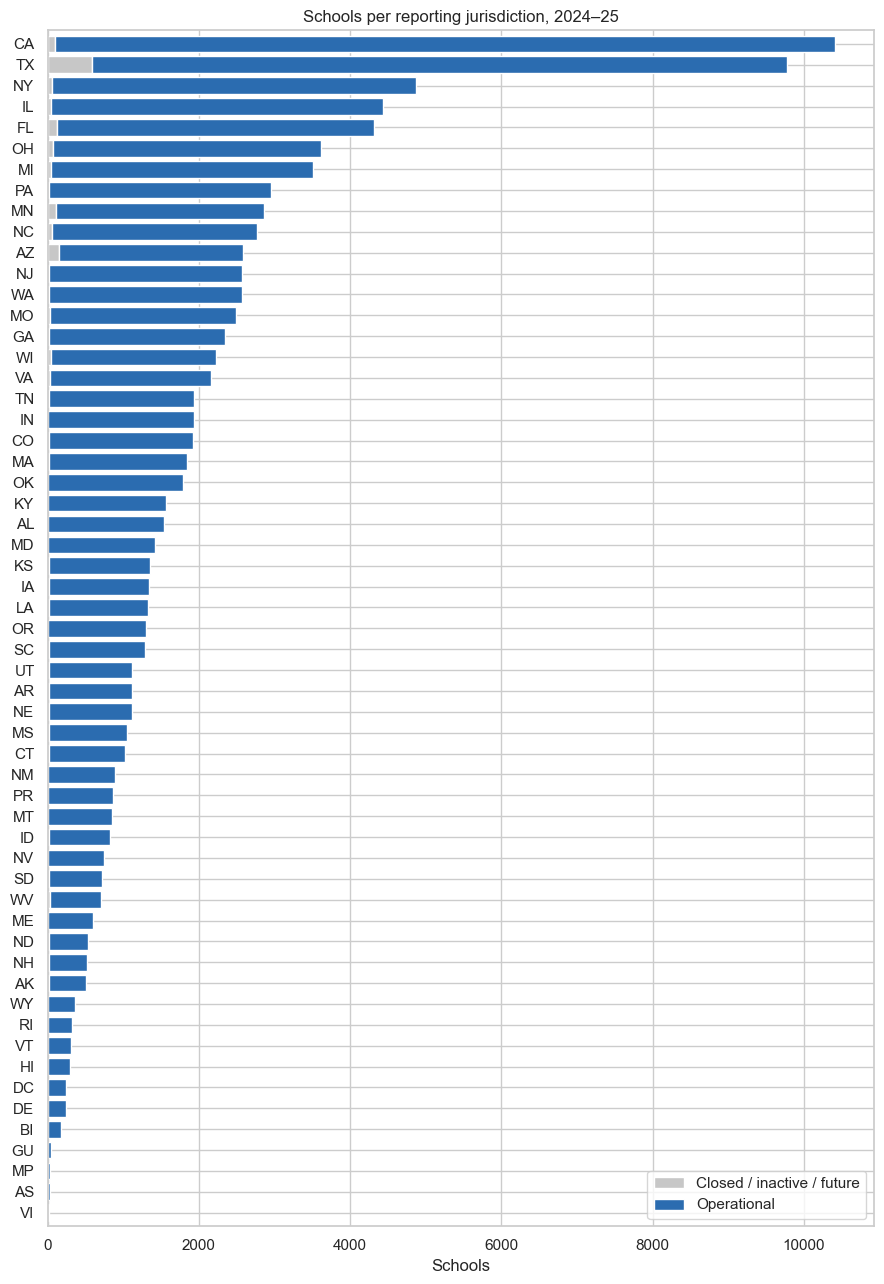

In [16]:
counts = schools.assign(
    status=np.where(schools["is_operational"], "Operational", "Closed / inactive / future")
).pivot_table(index="admin_state", columns="status", values="school_id", aggfunc="size", fill_value=0)
counts = counts.loc[counts.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(9, 13))
counts.plot.barh(stacked=True, ax=ax, color=["#c7c7c7", "#2b6cb0"], width=0.8)
ax.set_title("Schools per reporting jurisdiction, 2024–25")
ax.set_xlabel("Schools")
ax.set_ylabel("")
ax.legend(title="", loc="lower right")
plt.tight_layout()
plt.show()

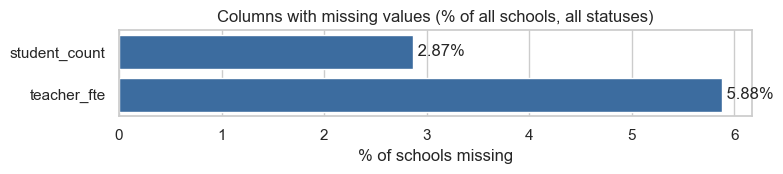

In [17]:
missing_share = (schools.isna().mean() * 100).sort_values()
missing_share = missing_share[missing_share > 0]

fig, ax = plt.subplots(figsize=(8, 0.45 * len(missing_share) + 1))
sns.barplot(x=missing_share.values, y=missing_share.index, color="#2b6cb0", ax=ax)
for position, value in enumerate(missing_share.values):
    ax.text(value, position, f" {value:.2f}%", va="center")
ax.set_title("Columns with missing values (% of all schools, all statuses)")
ax.set_xlabel("% of schools missing")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

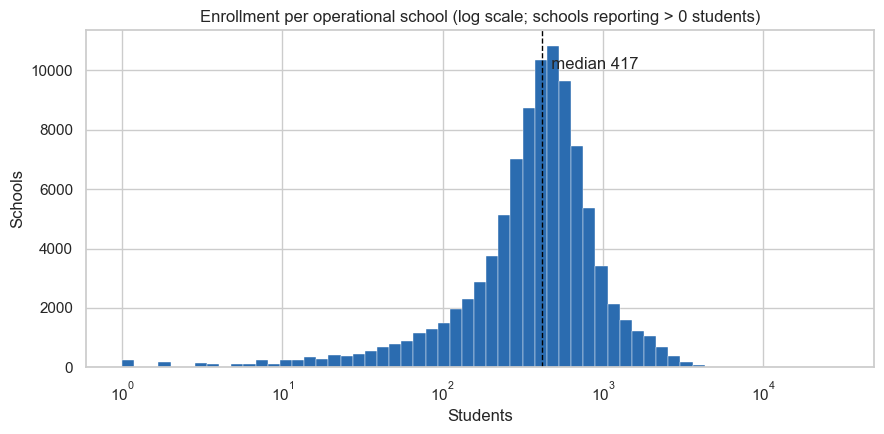

In [18]:
operational_enrollment = schools.loc[
    schools["is_operational"] & schools["student_count"].gt(0).fillna(False), "student_count"
].astype(float)

# Drawn with matplotlib directly: seaborn 0.12's histplot calls a pandas option that pandas 3 removed.
log_spaced_bins = np.logspace(0, np.log10(operational_enrollment.max()), 60)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(operational_enrollment, bins=log_spaced_bins, color="#2b6cb0", edgecolor="white", linewidth=0.3)
ax.set_xscale("log")
ax.set_ylabel("Schools")
ax.axvline(operational_enrollment.median(), color="black", linestyle="--", linewidth=1)
ax.text(
    operational_enrollment.median(),
    ax.get_ylim()[1] * 0.92,
    f"  median {operational_enrollment.median():,.0f}",
    va="top",
)
ax.set_title("Enrollment per operational school (log scale; schools reporting > 0 students)")
ax.set_xlabel("Students")
plt.tight_layout()
plt.show()

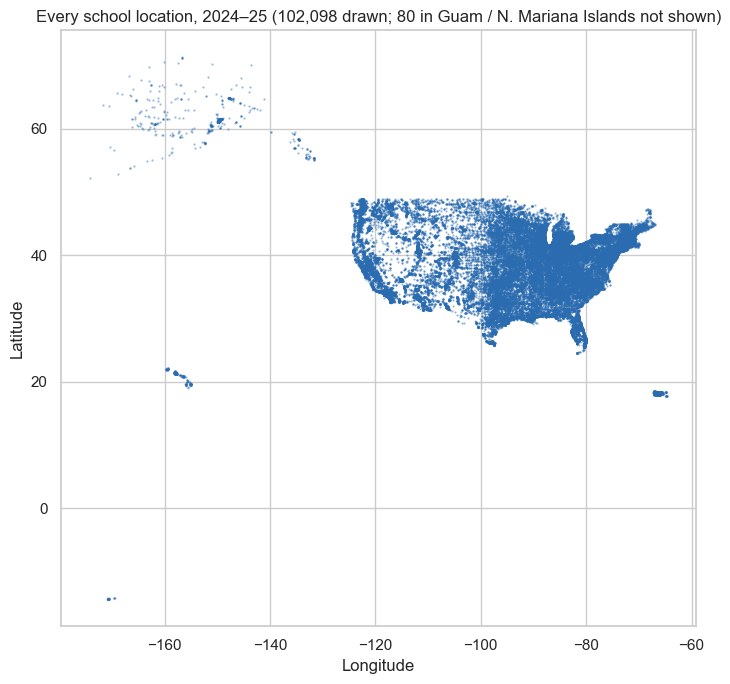

In [19]:
# Guam and the Northern Mariana Islands sit east of the 180° line; they are counted in the title rather than drawn.
western_hemisphere = schools["longitude"] < 0
pacific_east = (~western_hemisphere).sum()

fig, ax = plt.subplots(figsize=(13, 7))
ax.scatter(
    schools.loc[western_hemisphere, "longitude"],
    schools.loc[western_hemisphere, "latitude"],
    s=0.4,
    alpha=0.4,
    color="#2b6cb0",
)
ax.set_title(
    f"Every school location, 2024–25 ({western_hemisphere.sum():,} drawn; {pacific_east:,} in Guam / N. Mariana Islands not shown)"
)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect(1.2)
plt.tight_layout()
plt.show()

## 9. Save outputs

| File (in `data/interim/`) | One row per | Contents |
|---|---|---|
| `schools_2024_25.csv` | school (all statuses) | The combined school table |
| `school_data_checks_2024_25.csv` | school × check | Schools from section 6, with the reason |
| `jurisdiction_summary_2024_25.csv` | state / territory / BIE | Counts and totals from section 7 |

After writing, the school file is read back as text and compared with what was written, to prove that IDs kept their
leading zeros and no rows were lost.

In [20]:
INTERIM_DIR.mkdir(parents=True, exist_ok=True)
output_files = {
    f"schools_{SCHOOL_YEAR_LABEL}.csv": schools,
    f"school_data_checks_{SCHOOL_YEAR_LABEL}.csv": school_data_checks,
    f"jurisdiction_summary_{SCHOOL_YEAR_LABEL}.csv": jurisdiction_summary,
}
for file_name, frame in output_files.items():
    frame.to_csv(INTERIM_DIR / file_name, index=False)

reread = pd.read_csv(INTERIM_DIR / f"schools_{SCHOOL_YEAR_LABEL}.csv", **CSV_TEXT_OPTIONS)
check(len(reread) == len(schools), "Saved school file lost rows.")
check(
    reread["school_id"].equals(schools["school_id"].reset_index(drop=True)),
    "Saved school file changed school_id values.",
)
check(
    reread["district_id"].equals(schools["district_id"].reset_index(drop=True)),
    "Saved school file changed district_id values.",
)

pd.DataFrame(
    {
        "rows": [len(frame) for frame in output_files.values()],
        "columns": [frame.shape[1] for frame in output_files.values()],
        "megabytes": [round((INTERIM_DIR / name).stat().st_size / 1e6, 1) for name in output_files],
    },
    index=list(output_files),
)

,rows,columns,megabytes
schools_2024_25.csv,102178,30,25.2
school_data_checks_2024_25.csv,3670,5,0.4
jurisdiction_summary_2024_25.csv,57,8,0.0


## 10. Data dictionary — `schools_2024_25.csv`

| Column | Source column | Meaning |
|---|---|---|
| `school_id` | directory `NCESSCH` | 12-character NCES school ID (text; keep leading zeros) |
| `district_id` | directory `LEAID` | 7-character NCES district ID |
| `school_name`, `district_name` | `SCH_NAME`, `LEA_NAME` | Names as reported |
| `admin_state` / `_name` / `_fips` | `ST`, `STATENAME`, `FIPST` | Jurisdiction that reports the school (`BI` = Bureau of Indian Education) |
| `street`, `city`, `address_state`, `zipcode` | `LSTREET1`, `LCITY`, `LSTATE`, `LZIP` | Location (street) address of the school |
| `latitude`, `longitude` | EDGE `LAT`, `LON` | School point, decimal degrees |
| `location_state_fips`, `county_fips`, `county_name` | EDGE `STFIP`, `CNTY`, `NMCNTY` | State and county containing the point — use these for climate zones |
| `locale_code` | EDGE `LOCALE` | NCES urban-centric locale, 11 (City – Large) to 43 (Rural – Remote) |
| `status_start_of_year`, `status_updated` | `SY_STATUS_TEXT`, `UPDATED_STATUS_TEXT` | School status — see section 11 |
| `is_operational` | derived from `SY_STATUS` | True when the school is operating this year — see section 11 |
| `out_of_state_flag` | `OUT_OF_STATE_FLAG` | NCES marks schools located outside the reporting state |
| `school_type`, `charter`, `level` | `SCH_TYPE_TEXT`, `CHARTER_TEXT`, `LEVEL` | School classification; `level` drives the energy benchmark later |
| `lowest_grade`, `highest_grade` | `GSLO`, `GSHI` | Grade span |
| `student_count` | membership `STUDENT_COUNT` where `TOTAL_INDICATOR = Education Unit Total` | Total enrollment; blank when not available |
| `student_count_flag` | membership `DMS_FLAG` | Reported / Missing / Suppressed / Not reported / No record in file |
| `teacher_fte` | staff `TEACHERS` | Teacher full-time equivalents |
| `teacher_fte_flag` | staff `DMS_FLAG` | Same flag values as above |

## 11. Summary

**Terms used below**

- **Reporting jurisdiction** — who reports schools to NCES: the 50 states, DC, 5 territories (American Samoa, Guam,
  Northern Mariana Islands, Puerto Rico, U.S. Virgin Islands) and the Bureau of Indian Education. These are not
  counties.
- **School status** — each school's condition at the start of the 2024–25 school year, compared with NCES's previous
  report. Definitions from the [NCES CCD glossary](https://nces.ed.gov/ccd/commonfiles/glossary.asp):

  | Status | NCES definition | Operational? |
  |---|---|---|
  | Open | Was operational at the last report and is currently operational | Yes |
  | New | Has been opened since the last report | Yes |
  | Added | Was operational at the last report but was not on the CCD list at that time | Yes |
  | Changed Boundary/Agency | Was listed in the previous year as affiliated with a different education agency | Yes |
  | Reopened | Was closed on the previous year's file but has reopened | Yes |
  | Closed | Has closed since the last report | No |
  | Inactive | Temporarily closed (e.g. under construction); may reopen within three years | No |
  | Future | Scheduled to be operational within 2 years | No |

- **Operational school** — a school whose status is marked "Yes" above, i.e. actually operating this year. This is the
  set to use for energy analysis.
- **Teacher FTE** — full-time equivalents: two half-time teachers count as 1.0.
- **Operational schools flagged by data checks** — operating schools that failed at least one check in section 6
  (no enrollment, zero enrollment, or coordinates in another state). Each school is counted once, even if it fails
  more than one check. They stay in the data; each reason is listed in `school_data_checks_2024_25.csv`.

In [21]:
operational = schools[schools["is_operational"]]
summary = pd.Series(
    {
        "Reporting jurisdictions": f"{schools['admin_state'].nunique()}",
        "School districts (with at least one school)": f"{schools['district_id'].nunique():,}",
        "Schools (all statuses)": f"{len(schools):,}",
        "Operational schools": f"{len(operational):,}",
        "Students (all schools)": f"{schools['student_count'].sum():,}",
        "Teacher FTE (all schools)": f"{schools['teacher_fte'].sum():,.1f}",
        "Operational schools with coordinates": f"{operational['latitude'].notna().mean():.2%}",
        "Operational schools with enrollment": f"{operational['student_count'].notna().mean():.2%}",
        "Operational schools flagged by data checks": f"{school_data_checks['school_id'].nunique():,}",
    },
    name="2024–25",
)
summary.to_frame()

,2024–25
Reporting jurisdictions,57
School districts (with at least one school),"18,587"
Schools (all statuses),"102,178"
Operational schools,"100,237"
Students (all schools),"49,343,524"
Teacher FTE (all schools),"3,177,661.7"
Operational schools with coordinates,100.00%
Operational schools with enrollment,99.01%
Operational schools flagged by data checks,"3,669"


In [22]:
# Flags per check. A school can fail more than one check, so these add up to more than the number of flagged schools.
school_data_checks["check"].value_counts().reindex(CHECK_NAMES).to_frame("flags")

,flags
check,
enrollment_not_available,992
operational_school_reports_zero_students,2674
location_outside_admin_state,4
